In [1]:
# ==========================================
# TASK 1: MOLECULAR SOLUBILITY PREDICTION
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split


# Evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Saving models
import json
import os

# Reproducibility
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

DATA_PATH = PROJECT_DIR / "Data" / "delaney-processed.csv"

ARTIFACT_DIR = PROJECT_DIR / "artifacts"

MODEL_DIR = ARTIFACT_DIR / "models"
RESULTS_DIR = ARTIFACT_DIR / "results"
CHECKPOINT_DIR = ARTIFACT_DIR / "checkpoints"

for folder in [MODEL_DIR, RESULTS_DIR, CHECKPOINT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)
print("Artifacts directory:", ARTIFACT_DIR)

Project directory: d:\Visual analytics and Ai Project\Tutorial\Final Project IMplementation
Dataset path: d:\Visual analytics and Ai Project\Tutorial\Final Project IMplementation\Data\delaney-processed.csv
Artifacts directory: d:\Visual analytics and Ai Project\Tutorial\Final Project IMplementation\artifacts


In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())

Dataset loaded successfully!
Dataset shape: (1128, 10)
Missing values: 0
Duplicate rows: 0


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [4]:
TARGET = "measured log solubility in mols per litre"

FEATURES = [
    "Minimum Degree",
    "Molecular Weight",
    "Number of H-Bond Donors",
    "Number of Rings",
    "Number of Rotatable Bonds",
    "Polar Surface Area"
]

X = df[FEATURES].copy()

y = df[TARGET].copy()

print("Input features:", X.shape)
print("Target:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(TARGET)

Input features: (1128, 6)
Target: (1128,)

Selected features:
['Minimum Degree', 'Molecular Weight', 'Number of H-Bond Donors', 'Number of Rings', 'Number of Rotatable Bonds', 'Polar Surface Area']

Target variable:
measured log solubility in mols per litre


In [5]:
# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nSplit percentages:")
print(f"Training: {len(X_train) / len(df) * 100:.1f}%")
print(f"Validation: {len(X_val) / len(df) * 100:.1f}%")
print(f"Testing: {len(X_test) / len(df) * 100:.1f}%")

Training samples: 789
Validation samples: 169
Testing samples: 170

Split percentages:
Training: 69.9%
Validation: 15.0%
Testing: 15.1%


In [6]:
import torch
import torch_geometric
from rdkit import Chem

print("PyTorch:", torch.__version__)
print("PyTorch Geometric:", torch_geometric.__version__)
print("RDKit:", Chem.MolFromSmiles("CCO") is not None)

print("\nGNN environment ready!")

d:\Visual analytics and Ai Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Visual analytics and Ai Project\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.15.0+cpu
PyTorch Geometric: 2.8.1
RDKit: True

GNN environment ready!


In [7]:
from rdkit import Chem
import torch
from torch_geometric.data import Data

def smiles_to_graph(smiles, target):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # Atom features
    atom_features = []

    for atom in mol.GetAtoms():
        atom_features.append([
            atom.GetAtomicNum(),
            atom.GetDegree(),
            atom.GetFormalCharge(),
            atom.GetTotalNumHs(),
            int(atom.GetIsAromatic())
        ])

    x = torch.tensor(atom_features, dtype=torch.float)

    # Bond connections
    edge_indices = []

    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        edge_indices.append([i, j])
        edge_indices.append([j, i])

    if edge_indices:
        edge_index = torch.tensor(
            edge_indices, dtype=torch.long
        ).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    # Target value
    y = torch.tensor([target], dtype=torch.float)

    return Data(x=x, edge_index=edge_index, y=y)

In [8]:
def create_graph_dataset(X_split, y_split):
    graphs = []

    for idx in X_split.index:
        smiles = df.loc[idx, "smiles"]
        target = y_split.loc[idx]

        graph = smiles_to_graph(smiles, target)

        if graph is not None:
            graphs.append(graph)

    return graphs


train_graphs = create_graph_dataset(X_train, y_train)
val_graphs = create_graph_dataset(X_val, y_val)
test_graphs = create_graph_dataset(X_test, y_test)

print("Training graphs:", len(train_graphs))
print("Validation graphs:", len(val_graphs))
print("Testing graphs:", len(test_graphs))

print("\nExample molecular graph:")
print(train_graphs[0])

Training graphs: 789
Validation graphs: 169
Testing graphs: 170

Example molecular graph:
Data(x=[12, 5], edge_index=[2, 24], y=[1])


In [9]:
import torch.nn.functional as F
from torch.nn import Linear
from torch_geometric.nn import GCNConv, global_mean_pool

class GCN(torch.nn.Module):
    def __init__(self, hidden_channels=64, dropout=0.2):
        super().__init__()

        self.conv1 = GCNConv(5, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)

        self.lin1 = Linear(hidden_channels, 32)
        self.lin2 = Linear(32, 1)

        self.dropout = dropout

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        batch = data.batch

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = global_mean_pool(x, batch)

        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)

        return self.lin2(x).view(-1)


model = GCN(hidden_channels=64, dropout=0.2)

print(model)

GCN(
  (conv1): GCNConv(5, 64)
  (conv2): GCNConv(64, 64)
  (lin1): Linear(in_features=64, out_features=32, bias=True)
  (lin2): Linear(in_features=32, out_features=1, bias=True)
)


In [10]:
from torch_geometric.loader import DataLoader

# Training configuration
BATCH_SIZE = 32
EPOCHS = 100
LEARNING_RATE = 0.001

# Create data loaders
train_loader = DataLoader(
    train_graphs,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = GCN(hidden_channels=64, dropout=0.2).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = torch.nn.MSELoss()

print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("GNN training setup completed!")

Device: cpu
Training batches: 25
Validation batches: 6
Test batches: 6
GNN training setup completed!


In [11]:
from tqdm.auto import tqdm

train_losses = []
val_losses = []

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0

    for batch in loader:
        batch = batch.to(device)

        optimizer.zero_grad()

        predictions = model(batch)
        loss = criterion(predictions, batch.y.view(-1))

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch.num_graphs

    return total_loss / len(loader.dataset)


def evaluate_loss(model, loader, criterion, device):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)

            predictions = model(batch)
            loss = criterion(predictions, batch.y.view(-1))

            total_loss += loss.item() * batch.num_graphs

    return total_loss / len(loader.dataset)



In [12]:
import copy

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model, train_loader, optimizer, criterion, device
    )

    val_loss = evaluate_loss(
        model, val_loader, criterion, device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_model_state)

torch.save({
    "model_state_dict": best_model_state,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "hidden_channels": 64,
    "dropout": 0.2,
    "learning_rate": LEARNING_RATE
}, CHECKPOINT_DIR / "gcn_baseline.pt")

print("Best epoch:", best_epoch)
print("Best validation MSE:", round(best_val_loss, 4))
print("Checkpoint saved successfully!")
best_epoch = np.argmin(val_losses) + 1
best_val_loss = min(val_losses)

print("Best epoch:", best_epoch)
print("Best validation MSE:", round(best_val_loss, 4))
print("Best validation RMSE:", round(np.sqrt(best_val_loss), 4))


Best epoch: 98
Best validation MSE: 1.9549
Checkpoint saved successfully!
Best epoch: 98
Best validation MSE: 1.9549
Best validation RMSE: 1.3982


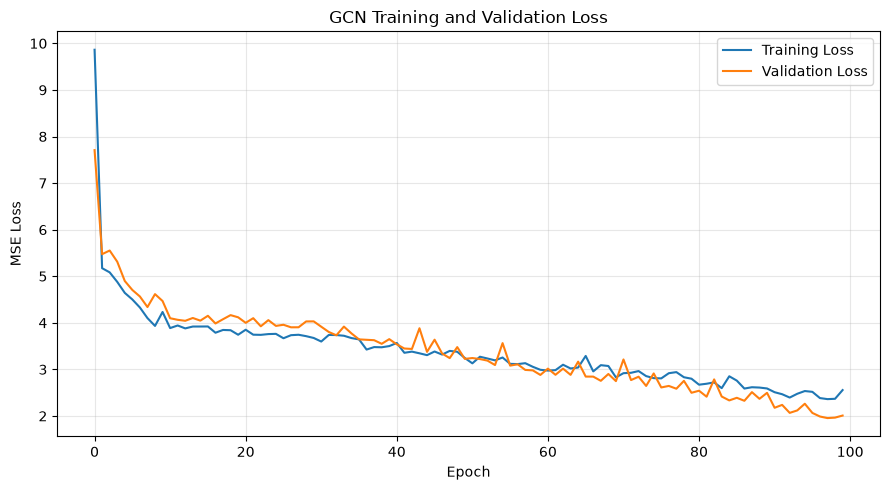

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("GCN Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

model.eval()

actual_values = []
predicted_values = []

with torch.no_grad():
    for batch in val_loader:
        batch = batch.to(device)

        predictions = model(batch)

        actual_values.extend(batch.y.view(-1).cpu().numpy())
        predicted_values.extend(predictions.cpu().numpy())

val_rmse = np.sqrt(
    mean_squared_error(actual_values, predicted_values)
)

val_mae = mean_absolute_error(
    actual_values, predicted_values
)

print("GCN Validation Results")
print("----------------------")
print(f"RMSE: {val_rmse:.4f} log S")
print(f"MAE:  {val_mae:.4f} log S")

GCN Validation Results
----------------------
RMSE: 1.3982 log S
MAE:  1.0922 log S


In [15]:
gcn_results = pd.DataFrame([{
    "Model": "GCN",
    "Architecture": "2-layer GCN",
    "Hidden Channels": 64,
    "Pooling": "Global Mean",
    "Dropout": 0.2,
    "Learning Rate": 0.001,
    "Best Epoch": best_epoch,
    "Validation RMSE": val_rmse,
    "Validation MAE": val_mae
}])

gcn_results.to_csv(
    RESULTS_DIR / "gcn_baseline_results.csv",
    index=False
)

display(gcn_results)

print("GCN validation results saved!")

,Model,Architecture,Hidden Channels,Pooling,Dropout,Learning Rate,Best Epoch,Validation RMSE,Validation MAE
0,GCN,2-layer GCN,64,Global Mean,0.2,0.001,98,1.398183,1.092236


GCN validation results saved!


In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Predict the training-set mean for every validation sample
baseline_predictions = np.full(
    len(y_val),
    y_train.mean()
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_predictions)
)

baseline_mae = mean_absolute_error(
    y_val, baseline_predictions
)

print("Mean Baseline Results")
print("---------------------")
print(f"RMSE: {baseline_rmse:.4f} log S")
print(f"MAE:  {baseline_mae:.4f} log S")

print("\nGCN Results")
print(f"RMSE: {val_rmse:.4f} log S")
print(f"MAE:  {val_mae:.4f} log S")

Mean Baseline Results
---------------------
RMSE: 2.2561 log S
MAE:  1.7939 log S

GCN Results
RMSE: 1.3982 log S
MAE:  1.0922 log S


In [17]:
comparison_results = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "Validation RMSE": baseline_rmse,
        "Validation MAE": baseline_mae
    },
    {
        "Model": "GCN",
        "Validation RMSE": val_rmse,
        "Validation MAE": val_mae
    }
])

comparison_results.to_csv(
    RESULTS_DIR / "baseline_comparison.csv",
    index=False
)

display(comparison_results)

,Model,Validation RMSE,Validation MAE
0,Mean Baseline,2.256142,1.793862
1,GCN,1.398183,1.092236


In [18]:
from torch_geometric.nn import SAGEConv, global_mean_pool

class GraphSAGE(torch.nn.Module):

    def __init__(self, hidden_channels=64, dropout=0.2):
        super().__init__()

        self.conv1 = SAGEConv(5, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, hidden_channels)

        self.lin1 = Linear(hidden_channels, 32)
        self.lin2 = Linear(32, 1)

        self.dropout = dropout

    def forward(self, data):

        x = data.x
        edge_index = data.edge_index
        batch = data.batch

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = global_mean_pool(x, batch)

        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)

        return self.lin2(x).view(-1)


sage_model = GraphSAGE(hidden_channels=64, dropout=0.2)

print(sage_model)


GraphSAGE(
  (conv1): SAGEConv(5, 64, aggr=mean)
  (conv2): SAGEConv(64, 64, aggr=mean)
  (lin1): Linear(in_features=64, out_features=32, bias=True)
  (lin2): Linear(in_features=32, out_features=1, bias=True)
)


In [19]:
# Reset GraphSAGE model
sage_model = GraphSAGE(
    hidden_channels=64,
    dropout=0.2
).to(device)

sage_optimizer = torch.optim.Adam(
    sage_model.parameters(),
    lr=LEARNING_RATE
)

sage_train_losses = []
sage_val_losses = []

best_sage_loss = float("inf")
best_sage_epoch = 0
best_sage_state = None

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        sage_model,
        train_loader,
        sage_optimizer,
        criterion,
        device
    )

    val_loss = evaluate_loss(
        sage_model,
        val_loader,
        criterion,
        device
    )

    sage_train_losses.append(train_loss)
    sage_val_losses.append(val_loss)

    if val_loss < best_sage_loss:
        best_sage_loss = val_loss
        best_sage_epoch = epoch + 1
        best_sage_state = copy.deepcopy(
            sage_model.state_dict()
        )

sage_model.load_state_dict(best_sage_state)

torch.save({
    "model_state_dict": best_sage_state,
    "best_epoch": best_sage_epoch,
    "best_val_loss": best_sage_loss,
    "hidden_channels": 64,
    "dropout": 0.2,
    "learning_rate": LEARNING_RATE
}, CHECKPOINT_DIR / "graphsage_baseline.pt")

print("GraphSAGE training completed!")
print("Best epoch:", best_sage_epoch)
print("Best validation MSE:", round(best_sage_loss, 4))

GraphSAGE training completed!
Best epoch: 89
Best validation MSE: 1.4306


In [20]:
sage_model.eval()

sage_actual = []
sage_predicted = []

with torch.no_grad():
    for batch in val_loader:
        batch = batch.to(device)

        predictions = sage_model(batch)

        sage_actual.extend(
            batch.y.view(-1).cpu().numpy()
        )
        sage_predicted.extend(
            predictions.cpu().numpy()
        )

sage_rmse = np.sqrt(
    mean_squared_error(sage_actual, sage_predicted)
)

sage_mae = mean_absolute_error(
    sage_actual, sage_predicted
)

print("GraphSAGE Validation Results")
print("-----------------------------")
print(f"RMSE: {sage_rmse:.4f} log S")
print(f"MAE:  {sage_mae:.4f} log S")

GraphSAGE Validation Results
-----------------------------
RMSE: 1.1961 log S
MAE:  0.9279 log S


In [21]:
architecture_results = pd.DataFrame([
    {
        "Model": "GCN",
        "Validation RMSE": val_rmse,
        "Validation MAE": val_mae
    },
    {
        "Model": "GraphSAGE",
        "Validation RMSE": sage_rmse,
        "Validation MAE": sage_mae
    }
])

architecture_results.to_csv(
    RESULTS_DIR / "gnn_architecture_comparison.csv",
    index=False
)

display(architecture_results)

,Model,Validation RMSE,Validation MAE
0,GCN,1.398183,1.092236
1,GraphSAGE,1.196079,0.927884


In [22]:
from torch_geometric.nn import GATConv

class GAT(torch.nn.Module):

    def __init__(self, hidden_channels=64, dropout=0.2):
        super().__init__()

        self.conv1 = GATConv(
            5, hidden_channels,
            heads=1,
            concat=False
        )

        self.conv2 = GATConv(
            hidden_channels, hidden_channels,
            heads=1,
            concat=False
        )

        self.lin1 = Linear(hidden_channels, 32)
        self.lin2 = Linear(32, 1)

        self.dropout = dropout

    def forward(self, data):

        x = data.x
        edge_index = data.edge_index
        batch = data.batch

        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(
            x, p=self.dropout,
            training=self.training
        )

        x = self.conv2(x, edge_index)
        x = F.elu(x)

        x = global_mean_pool(x, batch)

        x = F.relu(self.lin1(x))
        x = F.dropout(
            x, p=self.dropout,
            training=self.training
        )

        return self.lin2(x).view(-1)


gat_model = GAT(hidden_channels=64, dropout=0.2)

print(gat_model)

GAT(
  (conv1): GATConv(5, 64, heads=1)
  (conv2): GATConv(64, 64, heads=1)
  (lin1): Linear(in_features=64, out_features=32, bias=True)
  (lin2): Linear(in_features=32, out_features=1, bias=True)
)


In [23]:
gat_model = GAT(
    hidden_channels=64,
    dropout=0.2
).to(device)

gat_optimizer = torch.optim.Adam(
    gat_model.parameters(),
    lr=LEARNING_RATE
)

gat_train_losses = []
gat_val_losses = []

best_gat_loss = float("inf")
best_gat_epoch = 0
best_gat_state = None

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        gat_model,
        train_loader,
        gat_optimizer,
        criterion,
        device
    )

    val_loss = evaluate_loss(
        gat_model,
        val_loader,
        criterion,
        device
    )

    gat_train_losses.append(train_loss)
    gat_val_losses.append(val_loss)

    if val_loss < best_gat_loss:
        best_gat_loss = val_loss
        best_gat_epoch = epoch + 1
        best_gat_state = copy.deepcopy(
            gat_model.state_dict()
        )

gat_model.load_state_dict(best_gat_state)

torch.save({
    "model_state_dict": best_gat_state,
    "best_epoch": best_gat_epoch,
    "best_val_loss": best_gat_loss,
    "hidden_channels": 64,
    "dropout": 0.2,
    "learning_rate": LEARNING_RATE
}, CHECKPOINT_DIR / "gat_baseline.pt")

print("GAT training completed!")
print("Best epoch:", best_gat_epoch)
print("Best validation MSE:", round(best_gat_loss, 4))

GAT training completed!
Best epoch: 99
Best validation MSE: 1.7843


In [24]:
gat_model.eval()

gat_actual = []
gat_predicted = []

with torch.no_grad():
    for batch in val_loader:
        batch = batch.to(device)

        predictions = gat_model(batch)

        gat_actual.extend(
            batch.y.view(-1).cpu().numpy()
        )
        gat_predicted.extend(
            predictions.cpu().numpy()
        )

gat_rmse = np.sqrt(
    mean_squared_error(gat_actual, gat_predicted)
)

gat_mae = mean_absolute_error(
    gat_actual, gat_predicted
)

print("GAT Validation Results")
print("----------------------")
print(f"RMSE: {gat_rmse:.4f} log S")
print(f"MAE:  {gat_mae:.4f} log S")

GAT Validation Results
----------------------
RMSE: 1.3358 log S
MAE:  1.0244 log S


In [25]:
architecture_results = pd.DataFrame([
    {
        "Model": "GCN",
        "Validation RMSE": val_rmse,
        "Validation MAE": val_mae,
        "Best Epoch": best_epoch
    },
    {
        "Model": "GraphSAGE",
        "Validation RMSE": sage_rmse,
        "Validation MAE": sage_mae,
        "Best Epoch": best_sage_epoch
    },
    {
        "Model": "GAT",
        "Validation RMSE": gat_rmse,
        "Validation MAE": gat_mae,
        "Best Epoch": best_gat_epoch
    }
])

architecture_results.to_csv(
    RESULTS_DIR / "gnn_architecture_comparison.csv",
    index=False
)

display(architecture_results)

,Model,Validation RMSE,Validation MAE,Best Epoch
0,GCN,1.398183,1.092236,98
1,GraphSAGE,1.196079,0.927884,89
2,GAT,1.335783,1.024440,99


In [26]:
from torch_geometric.nn import global_max_pool, global_add_pool

class GraphSAGEPooling(torch.nn.Module):

    def __init__(self, pooling="mean", hidden_channels=64, dropout=0.2):
        super().__init__()

        self.conv1 = SAGEConv(5, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, hidden_channels)

        self.lin1 = Linear(hidden_channels, 32)
        self.lin2 = Linear(32, 1)

        self.dropout = dropout
        self.pooling = pooling

    def forward(self, data):

        x = data.x
        edge_index = data.edge_index
        batch = data.batch

        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = F.relu(self.conv2(x, edge_index))

        if self.pooling == "mean":
            x = global_mean_pool(x, batch)
        elif self.pooling == "max":
            x = global_max_pool(x, batch)
        elif self.pooling == "sum":
            x = global_add_pool(x, batch)

        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)

        return self.lin2(x).view(-1)

print("GraphSAGE pooling model ready!")

GraphSAGE pooling model ready!


In [27]:
pooling_results = []

for pooling_method in ["mean", "max", "sum"]:

    pooling_model = GraphSAGEPooling(
        pooling=pooling_method,
        hidden_channels=64,
        dropout=0.2
    ).to(device)

    pooling_optimizer = torch.optim.Adam(
        pooling_model.parameters(),
        lr=LEARNING_RATE
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(EPOCHS):

        train_one_epoch(
            pooling_model,
            train_loader,
            pooling_optimizer,
            criterion,
            device
        )

        current_val_loss = evaluate_loss(
            pooling_model,
            val_loader,
            criterion,
            device
        )

        if current_val_loss < best_loss:
            best_loss = current_val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(
                pooling_model.state_dict()
            )

    pooling_model.load_state_dict(best_state)
    pooling_model.eval()

    actual = []
    predicted = []

    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            predictions = pooling_model(batch)

            actual.extend(batch.y.view(-1).cpu().numpy())
            predicted.extend(predictions.cpu().numpy())

    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    pooling_results.append({
        "Pooling": pooling_method,
        "Best Epoch": best_epoch,
        "Validation RMSE": rmse,
        "Validation MAE": mae,
        "Validation R2": r2
    })

pooling_df = pd.DataFrame(pooling_results)

pooling_df.to_csv(
    RESULTS_DIR / "graphsage_pooling_comparison.csv",
    index=False
)

display(pooling_df)

,Pooling,Best Epoch,Validation RMSE,Validation MAE,Validation R2
0,mean,93,1.224809,0.951039,0.702174
1,max,2,2.590819,1.946294,-0.332598
2,sum,97,0.862626,0.677159,0.852270


In [28]:
# Save the actual Sum Pooling checkpoint

sum_results = pooling_df[
    pooling_df["Pooling"] == "sum"
].iloc[0]

torch.save({

    "model_state_dict": pooling_model.state_dict(),

    "architecture": "GraphSAGE",
    "pooling": "sum",
    "hidden_channels": 64,
    "dropout": 0.2,

    "best_epoch": int(sum_results["Best Epoch"]),

    "validation_rmse": float(
        sum_results["Validation RMSE"]
    ),

    "validation_mae": float(
        sum_results["Validation MAE"]
    ),

    "validation_r2": float(
        sum_results["Validation R2"]
    )

}, CHECKPOINT_DIR / "graphsage_sum_best.pt")

print("Actual Sum Pooling checkpoint saved!")

Actual Sum Pooling checkpoint saved!


In [29]:
hidden_results = []

for hidden_size in [64, 128]:

    hidden_model = GraphSAGEPooling(
        pooling="sum",
        hidden_channels=hidden_size,
        dropout=0.2
    ).to(device)

    hidden_optimizer = torch.optim.Adam(
        hidden_model.parameters(),
        lr=LEARNING_RATE
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(EPOCHS):

        train_one_epoch(
            hidden_model,
            train_loader,
            hidden_optimizer,
            criterion,
            device
        )

        current_loss = evaluate_loss(
            hidden_model,
            val_loader,
            criterion,
            device
        )

        if current_loss < best_loss:
            best_loss = current_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(
                hidden_model.state_dict()
            )

    hidden_model.load_state_dict(best_state)
    hidden_model.eval()

    actual, predicted = [], []

    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            predictions = hidden_model(batch)

            actual.extend(batch.y.view(-1).cpu().numpy())
            predicted.extend(predictions.cpu().numpy())

    hidden_results.append({
        "Hidden Channels": hidden_size,
        "Best Epoch": best_epoch,
        "Validation RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Validation MAE": mean_absolute_error(actual, predicted),
        "Validation R2": r2_score(actual, predicted)
    })

hidden_df = pd.DataFrame(hidden_results)

hidden_df.to_csv(
    RESULTS_DIR / "hidden_dimension_comparison.csv",
    index=False
)

display(hidden_df)

,Hidden Channels,Best Epoch,Validation RMSE,Validation MAE,Validation R2
0,64,98,0.879255,0.668285,0.846519
1,128,98,0.934983,0.707939,0.826447


In [30]:
# ==========================================================
# NEW CELL 1: FLEXIBLE GRAPHSAGE MODEL (VARIABLE LAYERS)
# Insert right below display(hidden_df) [Execution 120]
# ==========================================================

class GraphSAGEFlexible(torch.nn.Module):
    def __init__(self, num_layers=2, hidden_channels=64, dropout=0.2, pooling="sum"):
        super().__init__()
        self.convs = torch.nn.ModuleList()
        self.convs.append(SAGEConv(5, hidden_channels))
        for _ in range(num_layers - 1):
            self.convs.append(SAGEConv(hidden_channels, hidden_channels))

        self.lin1 = Linear(hidden_channels, 32)
        self.lin2 = Linear(32, 1)
        self.dropout = dropout
        self.pooling = pooling

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch

        for i, conv in enumerate(self.convs):
            x = F.relu(conv(x, edge_index))
            if i < len(self.convs) - 1:
                x = F.dropout(x, p=self.dropout, training=self.training)

        if self.pooling == "mean":
            x = global_mean_pool(x, batch)
        elif self.pooling == "max":
            x = global_max_pool(x, batch)
        elif self.pooling == "sum":
            x = global_add_pool(x, batch)

        x = F.relu(self.lin1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.lin2(x).view(-1)

print("Flexible GraphSAGE model ready for Layer, LR, and Dropout experiments!")

Flexible GraphSAGE model ready for Layer, LR, and Dropout experiments!


In [31]:
# ==========================================================
# NEW CELL 2: NUMBER OF LAYERS COMPARISON (2 vs 3 vs 4)
# ==========================================================

layer_results = []

for num_layers in [2, 3, 4]:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    layer_model = GraphSAGEFlexible(
        num_layers=num_layers,
        hidden_channels=64,
        dropout=0.2,
        pooling="sum"
    ).to(device)

    layer_optimizer = torch.optim.Adam(layer_model.parameters(), lr=LEARNING_RATE)

    best_loss = float("inf")
    best_state = None
    best_ep = 0

    for epoch in range(EPOCHS):
        train_one_epoch(layer_model, train_loader, layer_optimizer, criterion, device)
        val_loss = evaluate_loss(layer_model, val_loader, criterion, device)

        if val_loss < best_loss:
            best_loss = val_loss
            best_ep = epoch + 1
            best_state = copy.deepcopy(layer_model.state_dict())

    layer_model.load_state_dict(best_state)
    layer_model.eval()

    actual, predicted = [], []
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            actual.extend(batch.y.view(-1).cpu().numpy())
            predicted.extend(layer_model(batch).cpu().numpy())

    layer_results.append({
        "Layers": num_layers,
        "Best Epoch": best_ep,
        "Validation RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Validation MAE": mean_absolute_error(actual, predicted),
        "Validation R2": r2_score(actual, predicted)
    })

layer_df = pd.DataFrame(layer_results)
layer_df.to_csv(RESULTS_DIR / "layer_comparison.csv", index=False)
display(layer_df)

,Layers,Best Epoch,Validation RMSE,Validation MAE,Validation R2
0,2,98,0.877911,0.633649,0.846988
1,3,95,0.817601,0.616037,0.867289
2,4,97,0.787167,0.577488,0.876985


In [32]:
# ==========================================================
# NEW CELL 3: LEARNING RATE COMPARISON (0.0005 vs 0.001 vs 0.005)
# ==========================================================

lr_results = []

for lr_val in [0.0005, 0.001, 0.005]:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    lr_model = GraphSAGEPooling(
        pooling="sum",
        hidden_channels=64,
        dropout=0.2
    ).to(device)

    lr_optimizer = torch.optim.Adam(lr_model.parameters(), lr=lr_val)

    best_loss = float("inf")
    best_state = None
    best_ep = 0

    for epoch in range(EPOCHS):
        train_one_epoch(lr_model, train_loader, lr_optimizer, criterion, device)
        val_loss = evaluate_loss(lr_model, val_loader, criterion, device)

        if val_loss < best_loss:
            best_loss = val_loss
            best_ep = epoch + 1
            best_state = copy.deepcopy(lr_model.state_dict())

    lr_model.load_state_dict(best_state)
    lr_model.eval()

    actual, predicted = [], []
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            actual.extend(batch.y.view(-1).cpu().numpy())
            predicted.extend(lr_model(batch).cpu().numpy())

    lr_results.append({
        "Learning Rate": lr_val,
        "Best Epoch": best_ep,
        "Validation RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Validation MAE": mean_absolute_error(actual, predicted),
        "Validation R2": r2_score(actual, predicted)
    })

lr_df = pd.DataFrame(lr_results)
lr_df.to_csv(RESULTS_DIR / "learning_rate_comparison.csv", index=False)
display(lr_df)

,Learning Rate,Best Epoch,Validation RMSE,Validation MAE,Validation R2
0,0.0005,79,0.969385,0.735117,0.813440
1,0.0010,98,0.877911,0.633649,0.846988
2,0.0050,96,0.770038,0.584871,0.882280


In [33]:
# ==========================================================
# NEW CELL 4: DROPOUT COMPARISON (0.0 vs 0.2 vs 0.4)
# ==========================================================

dropout_results = []

for drop_val in [0.0, 0.2, 0.4]:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    drop_model = GraphSAGEPooling(
        pooling="sum",
        hidden_channels=64,
        dropout=drop_val
    ).to(device)

    drop_optimizer = torch.optim.Adam(drop_model.parameters(), lr=LEARNING_RATE)

    best_loss = float("inf")
    best_state = None
    best_ep = 0

    for epoch in range(EPOCHS):
        train_one_epoch(drop_model, train_loader, drop_optimizer, criterion, device)
        val_loss = evaluate_loss(drop_model, val_loader, criterion, device)

        if val_loss < best_loss:
            best_loss = val_loss
            best_ep = epoch + 1
            best_state = copy.deepcopy(drop_model.state_dict())

    drop_model.load_state_dict(best_state)
    drop_model.eval()

    actual, predicted = [], []
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            actual.extend(batch.y.view(-1).cpu().numpy())
            predicted.extend(drop_model(batch).cpu().numpy())

    dropout_results.append({
        "Dropout": drop_val,
        "Best Epoch": best_ep,
        "Validation RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Validation MAE": mean_absolute_error(actual, predicted),
        "Validation R2": r2_score(actual, predicted)
    })

dropout_df = pd.DataFrame(dropout_results)
dropout_df.to_csv(RESULTS_DIR / "dropout_comparison.csv", index=False)
display(dropout_df)

,Dropout,Best Epoch,Validation RMSE,Validation MAE,Validation R2
0,0.0,92,0.723698,0.534476,0.896023
1,0.2,98,0.877911,0.633649,0.846988
2,0.4,98,0.994728,0.738755,0.803558


In [34]:
# Reproducible final training
SEED = 42
# Select best hidden dimension using validation RMSE

best_hidden_row = hidden_df.loc[
    hidden_df["Validation RMSE"].idxmin()
]

BEST_HIDDEN = int(
    best_hidden_row["Hidden Channels"]
)

print("Selected hidden channels:", BEST_HIDDEN)
print(
    "Best validation RMSE:",
    best_hidden_row["Validation RMSE"]
)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Initialize final model from scratch

final_model = GraphSAGEPooling(
    pooling="sum",
    hidden_channels=BEST_HIDDEN,
    dropout=0.2
).to(device)

final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=0.001
)

best_final_loss = float("inf")
best_final_epoch = 0
best_final_state = None

final_train_losses = []
final_val_losses = []

for epoch in range(100):

    train_loss = train_one_epoch(
        final_model,
        train_loader,
        final_optimizer,
        criterion,
        device
    )

    val_loss = evaluate_loss(
        final_model,
        val_loader,
        criterion,
        device
    )

    final_train_losses.append(train_loss)
    final_val_losses.append(val_loss)

    if val_loss < best_final_loss:
        best_final_loss = val_loss
        best_final_epoch = epoch + 1
        best_final_state = copy.deepcopy(
            final_model.state_dict()
        )

final_model.load_state_dict(best_final_state)

# Save final checkpoint
torch.save({
    "model_state_dict": best_final_state,
    "architecture": "GraphSAGE",
    "pooling": "sum",
    "hidden_channels": BEST_HIDDEN,
    "dropout": 0.2,
    "learning_rate": 0.001,
    "best_epoch": best_final_epoch,
    "best_validation_mse": best_final_loss
}, CHECKPOINT_DIR / "final_graphsage_model.pt")

print("Final model training completed!")
print("Best epoch:", best_final_epoch)
print("Best validation RMSE:", round(np.sqrt(best_final_loss), 4))
print("Final checkpoint saved!")

Selected hidden channels: 64
Best validation RMSE: 0.8792546019673697
Final model training completed!
Best epoch: 98
Best validation RMSE: 0.8779
Final checkpoint saved!


In [35]:
final_model.eval()

test_actual = []
test_predicted = []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)

        predictions = final_model(batch)

        test_actual.extend(
            batch.y.view(-1).cpu().numpy()
        )

        test_predicted.extend(
            predictions.cpu().numpy()
        )

test_rmse = np.sqrt(
    mean_squared_error(test_actual, test_predicted)
)

test_mae = mean_absolute_error(
    test_actual, test_predicted
)

test_r2 = r2_score(
    test_actual, test_predicted
)

# Accuracy-like measures with explicitly defined tolerances
errors = np.abs(
    np.array(test_actual) - np.array(test_predicted)
)

within_05 = np.mean(errors <= 0.5) * 100
within_10 = np.mean(errors <= 1.0) * 100

print("FINAL TEST RESULTS")
print("==================")
print(f"Test RMSE: {test_rmse:.4f} log S")
print(f"Test MAE: {test_mae:.4f} log S")
print(f"Test R2: {test_r2:.4f}")
print(f"Within ±0.5 log S: {within_05:.2f}%")
print(f"Within ±1.0 log S: {within_10:.2f}%")

FINAL TEST RESULTS
Test RMSE: 0.9559 log S
Test MAE: 0.6727 log S
Test R2: 0.7763
Within ±0.5 log S: 51.18%
Within ±1.0 log S: 77.65%


In [36]:
import numpy as np

actual = np.array(test_actual)
predicted = np.array(test_predicted)

# Absolute prediction errors
errors = np.abs(actual - predicted)

# Accuracy within different error tolerances
accuracy_05 = np.mean(errors <= 0.5) * 100
accuracy_10 = np.mean(errors <= 1.0) * 100
accuracy_15 = np.mean(errors <= 1.5) * 100
accuracy_20 = np.mean(errors <= 2.0) * 100

print("MODEL ACCURACY (ERROR TOLERANCE)")
print("================================")
print(f"Accuracy within ±0.5 log S: {accuracy_05:.2f}%")
print(f"Accuracy within ±1.0 log S: {accuracy_10:.2f}%")
print(f"Accuracy within ±1.5 log S: {accuracy_15:.2f}%")
print(f"Accuracy within ±2.0 log S: {accuracy_20:.2f}%")

MODEL ACCURACY (ERROR TOLERANCE)
Accuracy within ±0.5 log S: 51.18%
Accuracy within ±1.0 log S: 77.65%
Accuracy within ±1.5 log S: 92.35%
Accuracy within ±2.0 log S: 95.88%


In [37]:
final_results = pd.DataFrame([{
    "Model": "GraphSAGE",
    "Test RMSE": test_rmse,
    "Test MAE": test_mae,
    "Test R2": test_r2,
    "Accuracy ±0.5 (%)": accuracy_05,
    "Accuracy ±1.0 (%)": accuracy_10,
    "Accuracy ±1.5 (%)": accuracy_15,
    "Accuracy ±2.0 (%)": accuracy_20
}])

display(final_results)

final_results.to_csv(
    RESULTS_DIR / "final_model_results.csv",
    index=False
)

,Model,Test RMSE,Test MAE,Test R2,Accuracy ±0.5 (%),Accuracy ±1.0 (%),Accuracy ±1.5 (%),Accuracy ±2.0 (%)
0,GraphSAGE,0.95592,0.672742,0.776327,51.176471,77.647059,92.352941,95.882353


In [38]:
# ==========================================================
# CELL 36: EXPORT DATA FOR FUTURE TASK 1 DASHBOARD CHARTS
# (Does NOT retrain or change your 0.9559 Test RMSE)
# ==========================================================

# 1. Save training & validation loss curves from Cell 32
curves_df = pd.DataFrame({
    "Epoch": range(1, len(final_train_losses) + 1),
    "Train_MSE": final_train_losses,
    "Validation_MSE": final_val_losses,
    "Train_RMSE": np.sqrt(final_train_losses),
    "Validation_RMSE": np.sqrt(final_val_losses)
})
curves_df.to_csv(RESULTS_DIR / "final_training_curves.csv", index=False)

# 2. Save molecule-level predictions & Split IDs for Question 1 charts
def get_split_predictions(model, graphs, split_indices, split_name):
    model.eval()
    loader = DataLoader(graphs, batch_size=BATCH_SIZE, shuffle=False)
    preds = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            preds.extend(model(batch).cpu().numpy())

    sub_df = df.loc[split_indices].copy()
    sub_df["Molecule_Index"] = sub_df.index
    sub_df["Split"] = split_name
    sub_df["Measured_logS"] = sub_df[TARGET]
    sub_df["Predicted_logS"] = preds
    sub_df["Error (Pred - Actual)"] = sub_df["Predicted_logS"] - sub_df["Measured_logS"]
    sub_df["Absolute_Error"] = sub_df["Error (Pred - Actual)"].abs()
    return sub_df

mol_predictions_df = pd.concat([
    get_split_predictions(final_model, train_graphs, X_train.index, "Train"),
    get_split_predictions(final_model, val_graphs, X_val.index, "Validation"),
    get_split_predictions(final_model, test_graphs, X_test.index, "Test")
], ignore_index=True)

mol_predictions_df.to_csv(RESULTS_DIR / "molecule_predictions.csv", index=False)
mol_predictions_df[["Molecule_Index", "Compound ID", "smiles", "Split"]].to_csv(
    RESULTS_DIR / "split_ids.csv", index=False
)

print("All files for future dashboard charts saved successfully!")

All files for future dashboard charts saved successfully!


In [40]:
# ==========================================================
# NEW CELL 5: SPLIT INVESTIGATION (SEPARATING SPLIT EFFECTS FROM MODEL CHANGES)
# Insert at the very bottom of the notebook (below Execution 125)
# ==========================================================

split_configs = [
    {"Split_Name": "70/15/15 (Seed 42)",  "test_temp": 0.30, "seed": 42},
    {"Split_Name": "70/15/15 (Seed 100)", "test_temp": 0.30, "seed": 100},
    {"Split_Name": "80/10/10 (Seed 42)",  "test_temp": 0.20, "seed": 42},
]

split_comparison_rows = []

for cfg in split_configs:
    s_name = cfg["Split_Name"]
    s_seed = cfg["seed"]
    t_size = cfg["test_temp"]

    # Create split
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=t_size, random_state=s_seed)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=s_seed)

    tr_graphs = create_graph_dataset(X_tr, y_tr)
    va_graphs = create_graph_dataset(X_va, y_va)
    te_graphs = create_graph_dataset(X_te, y_te)

    tr_loader = DataLoader(tr_graphs, batch_size=BATCH_SIZE, shuffle=True)
    va_loader = DataLoader(va_graphs, batch_size=BATCH_SIZE, shuffle=False)
    te_loader = DataLoader(te_graphs, batch_size=BATCH_SIZE, shuffle=False)

    # Compare GCN vs GraphSAGE (Sum) within each split
    for model_label in ["GCN (Mean Pool)", "GraphSAGE (Sum Pool)"]:
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)

        if model_label == "GCN (Mean Pool)":
            m = GCN(hidden_channels=64, dropout=0.2).to(device)
        else:
            m = GraphSAGEPooling(pooling="sum", hidden_channels=64, dropout=0.2).to(device)

        opt = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE)
        best_v_loss = float("inf")
        best_v_state = None

        for ep in range(EPOCHS):
            train_one_epoch(m, tr_loader, opt, criterion, device)
            v_loss = evaluate_loss(m, va_loader, criterion, device)
            if v_loss < best_v_loss:
                best_v_loss = v_loss
                best_v_state = copy.deepcopy(m.state_dict())

        m.load_state_dict(best_v_state)
        m.eval()

        # Evaluate on Validation and Test for this split
        def eval_split_metrics(loader_obj):
            act, pred = [], []
            with torch.no_grad():
                for b in loader_obj:
                    b = b.to(device)
                    act.extend(b.y.view(-1).cpu().numpy())
                    pred.extend(m(b).cpu().numpy())
            return (
                np.sqrt(mean_squared_error(act, pred)),
                mean_absolute_error(act, pred),
                r2_score(act, pred)
            )

        v_rmse, v_mae, v_r2 = eval_split_metrics(va_loader)
        t_rmse, t_mae, t_r2 = eval_split_metrics(te_loader)

        split_comparison_rows.append({
            "Split Setting": s_name,
            "Model": model_label,
            "Train Size": len(tr_graphs),
            "Val Size": len(va_graphs),
            "Test Size": len(te_graphs),
            "Validation RMSE (log S)": v_rmse,
            "Validation MAE (log S)": v_mae,
            "Test RMSE (log S)": t_rmse,
            "Test MAE (log S)": t_mae,
            "Test R2": t_r2
        })

split_comp_df = pd.DataFrame(split_comparison_rows)
split_comp_df.to_csv(RESULTS_DIR / "split_comparison.csv", index=False)
display(split_comp_df)
print("Split comparison saved to artifacts/results/split_comparison.csv!")

,Split Setting,Model,Train Size,Val Size,Test Size,Validation RMSE (log S),Validation MAE (log S),Test RMSE (log S),Test MAE (log S),Test R2
0,70/15/15 (Seed 42),GCN (Mean Pool),789,169,170,1.358328,1.121336,1.462130,1.193496,0.476710
1,70/15/15 (Seed 42),GraphSAGE (Sum Pool),789,169,170,0.877911,0.633649,0.955920,0.672742,0.776327
2,70/15/15 (Seed 100),GCN (Mean Pool),789,169,170,1.313447,1.023092,1.318981,1.048940,0.621013
3,70/15/15 (Seed 100),GraphSAGE (Sum Pool),789,169,170,0.843400,0.682042,0.851838,0.680617,0.841926
4,80/10/10 (Seed 42),GCN (Mean Pool),902,113,113,1.332812,1.041117,1.285841,1.014259,0.611638
5,80/10/10 (Seed 42),GraphSAGE (Sum Pool),902,113,113,0.899770,0.667047,0.935233,0.694070,0.794552


Split comparison saved to artifacts/results/split_comparison.csv!
